# Model training - SimpleRNN / GRU / LSTM on GOOGL
**DNN Project 2 - Group 1** | notebook 03

Trains the required SimpleRNN (64 units, tanh, dropout 0.2, Dense(1), Adam + MSE, early stopping on validation loss),
plus the optional GRU and LSTM on the same data and split, and compares all of them with a persistence baseline.
All metrics are computed in USD (after inverse scaling). Inputs come from notebook 02 (`../data/processed/`),
figures go to `../results/03_model_training/`.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, LSTM, Dropout, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

PROC_DIR = "../data/processed"
#pls run 02_preprocessing first so this folder exists, ty!
RESULTS_DIR = "../results/03_model_training"
os.makedirs(RESULTS_DIR, exist_ok=True)

BATCH_SIZE = 32
MAX_EPOCHS = 100
PATIENCE = 10

## 1. Load the preprocessed sequences

In [2]:
d = np.load(os.path.join(PROC_DIR, "sequences.npz"))
X_train, y_train = d["X_train"], d["y_train"]
X_val, y_val = d["X_val"], d["y_val"]
X_test, y_test = d["X_test"], d["y_test"]
dates_test = pd.to_datetime(d["dates_test"])
target_scaler = joblib.load(os.path.join(PROC_DIR, "target_scaler.joblib"))

print("features:", list(d["features"]), "| window:", int(d["window"]))
print("train", X_train.shape, y_train.shape)
print("val  ", X_val.shape, y_val.shape)
print("test ", X_test.shape, y_test.shape)

def to_usd(a):
    return target_scaler.inverse_transform(np.asarray(a).reshape(-1, 1)).ravel()

features: [np.str_('Close')] | window: 30
train (3071, 30, 1) (3071,)
val   (665, 30, 1) (665,)
test  (665, 30, 1) (665,)


## 2. Model builder and training helper
Same recipe for every architecture, only the recurrent layer changes:
`Input -> {SimpleRNN | GRU | LSTM}(64, tanh) -> Dropout(0.2) -> Dense(1)`.

In [3]:
LAYERS = {"SimpleRNN": SimpleRNN, "GRU": GRU, "LSTM": LSTM}

def build_model(kind, input_shape, units=64, dropout=0.2, lr=1e-3):
    model = Sequential([
        Input(shape=input_shape),
        LAYERS[kind](units, activation="tanh"),
        Dropout(dropout),
        Dense(1),
    ], name=kind)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss="mse", metrics=["mae"])
    return model

def train(model, X_tr, y_tr, X_va, y_va, epochs=MAX_EPOCHS, early_stop=True):
    cb = [EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)] if early_stop else []
    return model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=epochs,
                     batch_size=BATCH_SIZE, callbacks=cb, verbose=0, shuffle=False)
    #shuffle=False keeps batches in time order, runs are reproducible

def metrics_usd(y_true_scaled, y_pred_scaled):
    yt, yp = to_usd(y_true_scaled), to_usd(y_pred_scaled)
    mse = mean_squared_error(yt, yp)
    return {"MAE": mean_absolute_error(yt, yp), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(yt, yp)}

## 3. Persistence baseline
Predict tomorrow's close = today's close. Any model has to beat this to be worth anything.

In [4]:
persist_val = X_val[:, -1, 0]
persist_test = X_test[:, -1, 0]
results = {"Persistence": metrics_usd(y_test, persist_test)}
pd.DataFrame(results).T

,MAE,MSE,RMSE,R2
Persistence,24.790963,1264.90704,35.565532,0.996668


## 4. Train the three models

In [5]:
models, histories, preds = {}, {}, {}
for kind in ["SimpleRNN", "GRU", "LSTM"]:
    tf.keras.utils.set_random_seed(SEED)
    m = build_model(kind, X_train.shape[1:])
    h = train(m, X_train, y_train, X_val, y_val)
    models[kind], histories[kind] = m, h
    preds[kind] = m.predict(X_test, verbose=0).ravel()
    results[kind] = metrics_usd(y_test, preds[kind])
    best = int(np.argmin(h.history["val_loss"])) + 1
    print(f"{kind:<10} stopped after {len(h.history['loss'])} epochs, best epoch {best}, "
          f"best val_loss {min(h.history['val_loss']):.5f}")

models["SimpleRNN"].summary()

SimpleRNN  stopped after 39 epochs, best epoch 29, best val_loss 0.00057
GRU        stopped after 45 epochs, best epoch 35, best val_loss 0.00043
LSTM       stopped after 61 epochs, best epoch 51, best val_loss 0.00059


Model: "SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,869 (50.27 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,580 (33.52 KB)

## 5. Test-set results (USD)

In [6]:
res_df = pd.DataFrame(results).T[["MAE", "MSE", "RMSE", "R2"]]
res_df.to_csv(os.path.join(RESULTS_DIR, "test_metrics.csv"))
res_df.round(3)

,MAE,MSE,RMSE,R2
Persistence,24.791,1264.907,35.566,0.997
SimpleRNN,130.442,30423.373,174.423,0.920
GRU,95.087,18155.702,134.743,0.952
LSTM,56.697,5977.037,77.311,0.984


## 6. Loss curves

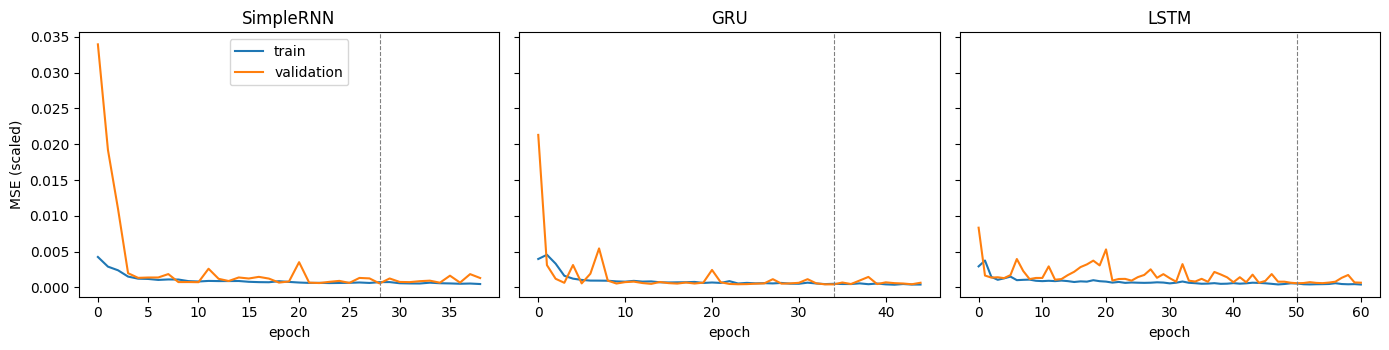

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (kind, h) in zip(axes, histories.items()):
    ax.plot(h.history["loss"], label="train")
    ax.plot(h.history["val_loss"], label="validation")
    ax.axvline(int(np.argmin(h.history["val_loss"])), color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(kind)
    ax.set_xlabel("epoch")
axes[0].set_ylabel("MSE (scaled)")
axes[0].legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "loss_curves.png"), dpi=150)
plt.show()

## 7. Actual vs predicted closing price (test set)

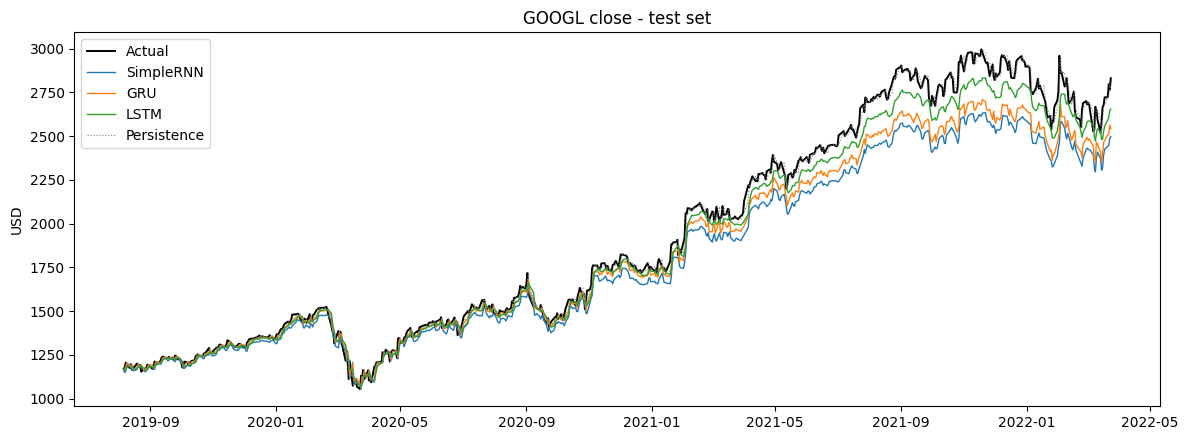

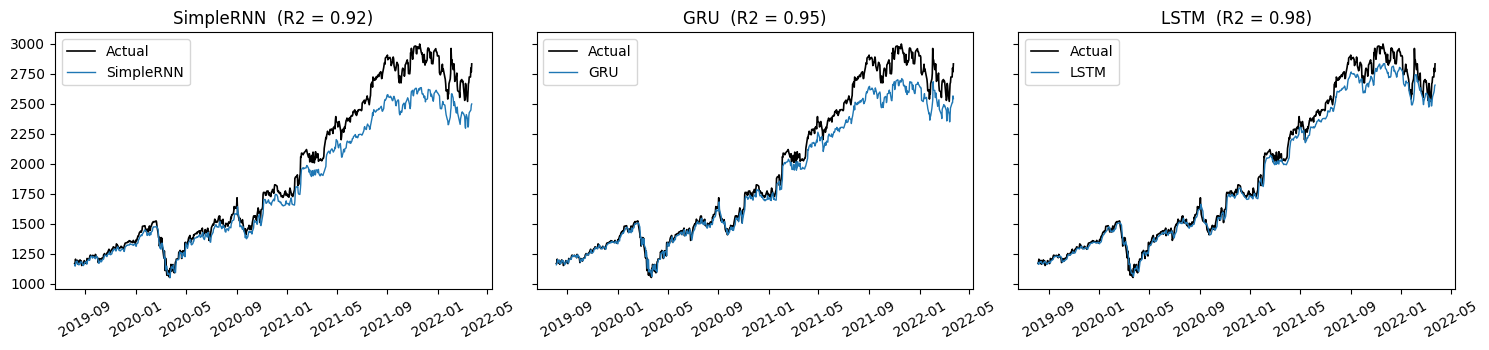

In [8]:
actual = to_usd(y_test)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(dates_test, actual, color="black", linewidth=1.4, label="Actual")
for kind in preds:
    ax.plot(dates_test, to_usd(preds[kind]), linewidth=1, label=kind)
ax.plot(dates_test, to_usd(persist_test), linewidth=0.8, linestyle=":", color="grey", label="Persistence")
ax.set_title("GOOGL close - test set")
ax.set_ylabel("USD")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "test_predictions.png"), dpi=150)
plt.show()

#one panel per model for the slides
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, kind in zip(axes, preds):
    ax.plot(dates_test, actual, color="black", linewidth=1.2, label="Actual")
    ax.plot(dates_test, to_usd(preds[kind]), linewidth=1, label=kind)
    ax.set_title(f"{kind}  (R2 = {results[kind]['R2']:.2f})")
    ax.legend()
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "test_predictions_per_model.png"), dpi=150)
plt.show()

## 8. Where do the errors come from?
Training prices stop at about 836 USD while the test period goes up to about 2,997 USD, so a large part of the test range
was never seen. Plotting the error over time shows whether the models fail uniformly or only once the price leaves the training range.

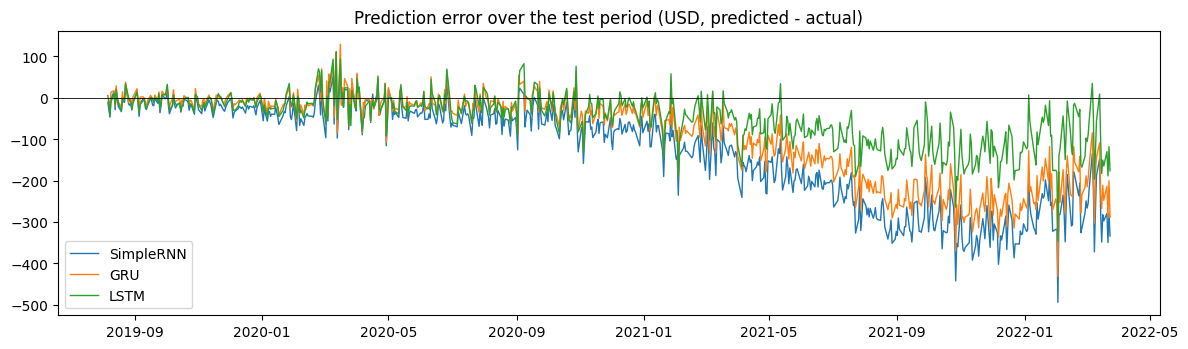

Test days above the highest training price (836 USD): 665 / 665


In [9]:
train_max_usd = float(target_scaler.data_max_[0])
fig, ax = plt.subplots(figsize=(12, 3.6))
for kind in preds:
    ax.plot(dates_test, to_usd(preds[kind]) - actual, linewidth=1, label=kind)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title("Prediction error over the test period (USD, predicted - actual)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "test_errors.png"), dpi=150)
plt.show()

above = actual > train_max_usd
print(f"Test days above the highest training price ({train_max_usd:.0f} USD): {above.sum()} / {len(actual)}")

## 9. Hyperparameter study (SimpleRNN, selection on validation)
One factor at a time around the baseline (64 units, lr 1e-3, window 30). The test set is **not** used to pick anything here.

In [10]:
def val_rmse_usd(model, X_va, y_va):
    return np.sqrt(mean_squared_error(to_usd(y_va), to_usd(model.predict(X_va, verbose=0).ravel())))

rows = []
#hidden units
for units in [16, 32, 64, 128]:
    tf.keras.utils.set_random_seed(SEED)
    m = build_model("SimpleRNN", X_train.shape[1:], units=units)
    h = train(m, X_train, y_train, X_val, y_val)
    rows.append({"Factor": "hidden units", "Value": str(units), "Epochs run": len(h.history["loss"]),
                 "Val RMSE (USD)": val_rmse_usd(m, X_val, y_val)})
#learning rate
for lr in [1e-2, 1e-3, 1e-4]:
    tf.keras.utils.set_random_seed(SEED)
    m = build_model("SimpleRNN", X_train.shape[1:], lr=lr)
    h = train(m, X_train, y_train, X_val, y_val)
    rows.append({"Factor": "learning rate", "Value": str(lr), "Epochs run": len(h.history["loss"]),
                 "Val RMSE (USD)": val_rmse_usd(m, X_val, y_val)})
#fixed number of epochs, no early stopping
for ep in [5, 20, 60]:
    tf.keras.utils.set_random_seed(SEED)
    m = build_model("SimpleRNN", X_train.shape[1:])
    train(m, X_train, y_train, X_val, y_val, epochs=ep, early_stop=False)
    rows.append({"Factor": "epochs (no early stop)", "Value": str(ep), "Epochs run": ep,
                 "Val RMSE (USD)": val_rmse_usd(m, X_val, y_val)})
hp = pd.DataFrame(rows)

Sequence length needs new windows, so rebuild them from the CSV with the **same** train-fitted scaler and the same
split rule as notebook 02 (targets stay inside their own split).

In [11]:
raw = pd.read_csv("../data/GOOGL.csv", parse_dates=["Date"]).sort_values("Date").reset_index(drop=True)
close_scaled = target_scaler.transform(raw[["Close"]]).ravel()
n = len(raw)
tr_end, va_end = int(n * 0.70), int(n * 0.85)

def windows(window):
    X, y, t = [], [], []
    for i in range(window, n):
        X.append(close_scaled[i - window:i]); y.append(close_scaled[i]); t.append(i)
    X, y, t = np.array(X)[..., None], np.array(y), np.array(t)
    return {k: (X[(t >= a) & (t < b)], y[(t >= a) & (t < b)]) for k, (a, b) in
            {"tr": (0, tr_end), "va": (tr_end, va_end), "te": (va_end, n)}.items()}

#sanity: window 30 must reproduce notebook 02
w30 = windows(30)
assert np.allclose(w30["tr"][0], X_train) and np.allclose(w30["te"][1], y_test)

rows = []
for window in [10, 20, 30, 60]:
    w = windows(window)
    tf.keras.utils.set_random_seed(SEED)
    m = build_model("SimpleRNN", w["tr"][0].shape[1:])
    h = train(m, *w["tr"], *w["va"])
    rows.append({"Factor": "sequence length", "Value": str(window), "Epochs run": len(h.history["loss"]),
                 "Val RMSE (USD)": val_rmse_usd(m, *w["va"])})
hp = pd.concat([hp, pd.DataFrame(rows)], ignore_index=True)
hp.to_csv(os.path.join(RESULTS_DIR, "hyperparameter_study.csv"), index=False)
hp.round(3)

,Factor,Value,Epochs run,Val RMSE (USD)
0,hidden units,16,67,29.821
1,hidden units,32,64,26.961
2,hidden units,64,39,18.682
3,hidden units,128,18,22.065
4,learning rate,0.01,18,170.026
5,learning rate,0.001,39,18.682
6,learning rate,0.0001,26,78.750
7,epochs (no early stop),5,5,28.821
8,epochs (no early stop),20,20,22.806
9,epochs (no early stop),60,60,21.125


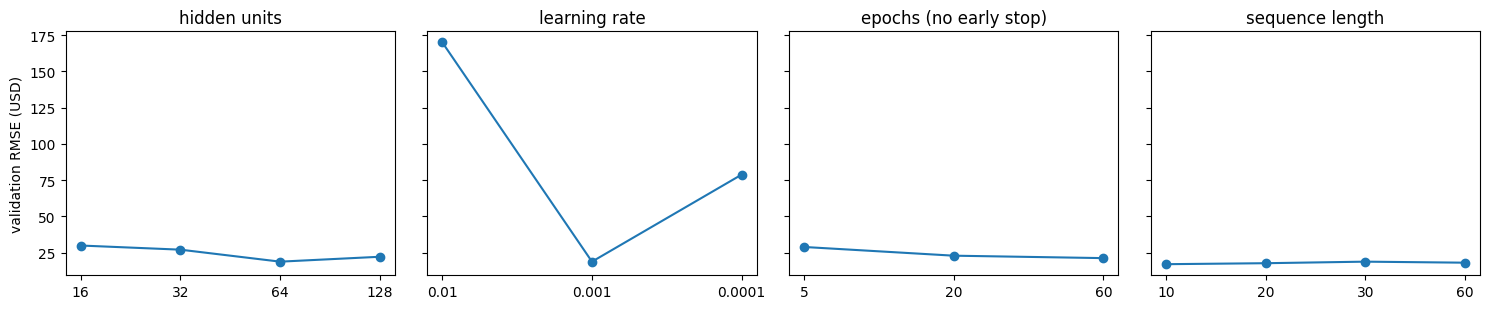

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, (factor, g) in zip(axes, hp.groupby("Factor", sort=False)):
    ax.plot(g["Value"], g["Val RMSE (USD)"], marker="o")
    ax.set_title(factor)
axes[0].set_ylabel("validation RMSE (USD)")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "hyperparameter_study.png"), dpi=150)
plt.show()

## 10. Save models

In [13]:
os.makedirs("../models", exist_ok=True)
for kind, m in models.items():
    m.save(f"../models/{kind.lower()}.keras")
print(sorted(os.listdir("../models")))

['gru.keras', 'lstm.keras', 'simplernn.keras']
